In [2]:
import os
import sys

import numpy as np
import scope
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('..'))
from local_functions import *

## User Configuration

In [3]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                                                          # Update with your path
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy"                                       # Update with your path

debug_sys_name = "TEPVIW"

# Normalizes the configured strings.
data_path = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path  = os.path.abspath(os.path.expanduser(env_path))

# Loads Environment
env = scope.load_binary(env_path)

# Path of the system inspected in this notebook
debug_system_path = data_path + f"2-Systems/{debug_sys_name}/{debug_sys_name}.npy"

print(f"Data directory:    {data_path}")
print(f"SCOPE environment: {env_path}")

Data directory:    /Users/sergivela/Documents/SCOPE/ATLAS/Data/
SCOPE environment: /Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy


## Loads and Prepares System

In [34]:
debug_sys      = scope.load_binary(debug_system_path)
debug_sys.set_paths_from_environment(env)

True

In [35]:
hs_min = find_optimized_minimum(debug_sys.find_source("ref_hs_mol")[1])[1]
ls_min = find_optimized_minimum(debug_sys.find_source("ref_ls_mol")[1])[1]

In [36]:
for st in list([hs_min, ls_min]):
    for comp in st.computations:
        if comp.type == "freq":
            if not hasattr(comp,"output"): comp.create_output()
            VNMs = comp.output.get_vnms(witheigen=True)
            st.set_VNMs(VNMs)

## Reordered

In [24]:
from scope.vnm_tools import map_vnms

scale = 100
penalty = 1.25

hs_vnms = hs_min.VNMs
ls_vnms = ls_min.VNMs

vnmsA_ordered, vnmsB_ordered, results = map_vnms(hs_vnms, ls_vnms, hs_min.labels, hs_min.coord, ls_min.labels, ls_min.coord, adjmatA=hs_min.molecules[0].adjmat, adjmatB=ls_min.molecules[0].adjmat, f_scale=scale, f_weight=penalty)
print(scale, penalty, assess_vnm_mapping(results["mappings"]))

100 1.25 {'mapping_quality': 0.8050870817355992, 'mean_cost': 0.21680483134511538, 'mean_overlap': 0.812532285661937, 'mean_squared_overlap': 0.6787439155875652, 'median_overlap': 0.8430947785636252, 'minimum_overlap': 0.2275174559230365, 'overlap_10th_percentile': 0.6142022816631177, 'fraction_overlap_above_0.8': 0.6255144032921811, 'fraction_overlap_above_0.5': 0.9711934156378601, 'frequency_mae': 7.952445679012341, 'frequency_rmse': 15.319821671821762, 'maximum_frequency_difference': 85.66910000000001}


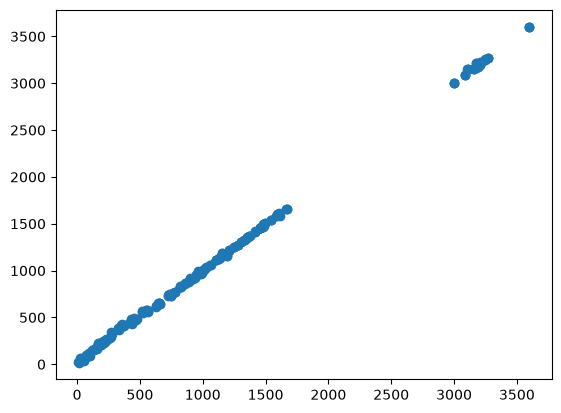

In [8]:
freq_A = [item["freqA"] for item in results["mappings"]]
freq_B = [item["freqB"] for item in results["mappings"]]
plt.scatter(freq_A, freq_B)

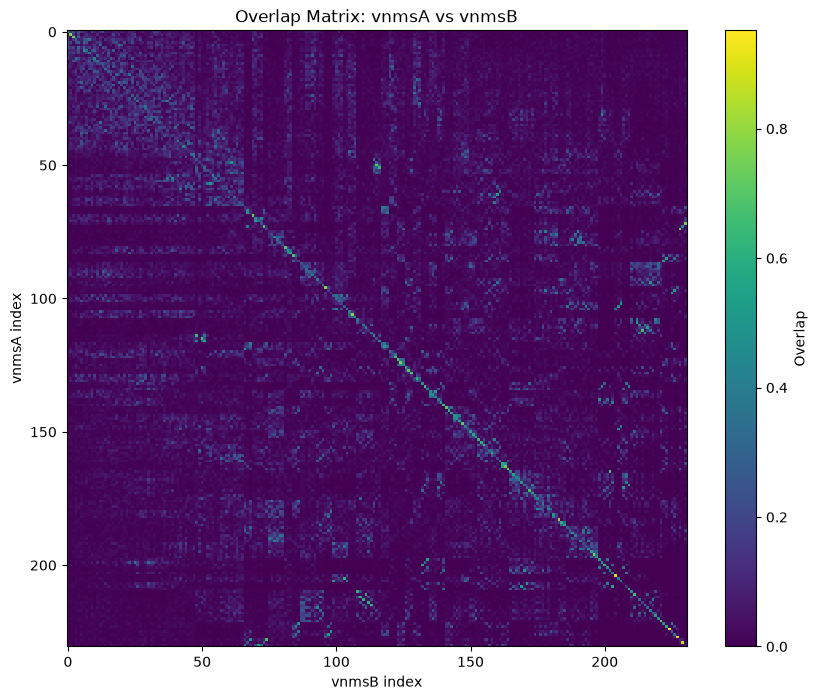

In [9]:
scope.classes_qc.plot_overlap_vnms(vnmsA_ordered, vnmsB_ordered)

## Projection onto the 15-dimensional FeN$_6$ internal subspace

The seven atoms in the first coordination sphere span 21 Cartesian directions. The six rigid FeN$_6$ translation/rotation directions are used only to define their orthogonal complement, leaving a 15-dimensional internal-deformation basis. Each full-molecule normal mode is mass weighted, normalized, restricted to the FeN$_6$ atoms, and projected onto this basis.

The sum of the internal projection weights over a complete set of molecular VNMs should be approximately 15. The weight can nevertheless be distributed over substantially more than 15 VNMs.

In [10]:
def get_fcs_internal_basis(coords, masses):
    coords = np.asarray(coords, dtype=float)
    masses = np.asarray(masses, dtype=float)
    sqrt_masses = np.sqrt(masses)

    center_of_mass = np.average(coords, axis=0, weights=masses)
    centered_coords = coords - center_of_mass

    rigid_vectors = []
    for axis in np.eye(3):
        rigid_vectors.append((sqrt_masses[:, None] * axis).reshape(-1))
    for axis in np.eye(3):
        rotation = np.cross(axis, centered_coords)
        rigid_vectors.append((sqrt_masses[:, None] * rotation).reshape(-1))

    rigid_vectors = np.asarray(rigid_vectors).T
    left_vectors, singular_values, _ = np.linalg.svd(rigid_vectors, full_matrices=True)
    tolerance = max(rigid_vectors.shape) * np.finfo(float).eps * singular_values[0]
    rigid_rank = np.count_nonzero(singular_values > tolerance)
    if rigid_rank != 6:
        raise ValueError(f'Expected six independent rigid directions, found {rigid_rank}')

    return left_vectors[:, rigid_rank:]

def project_vnms_on_fcs(vnms, coords, fcs_indices):
    masses = np.asarray(vnms[0].masses, dtype=float)[fcs_indices]
    internal_basis = get_fcs_internal_basis(np.asarray(coords)[fcs_indices], masses)

    fcs_weights = []
    internal_weights = []
    for vnm in vnms:
        mode = vnm.mass_weight_mode(permanent=False)
        mode = mode / np.linalg.norm(mode)
        fcs_mode = mode[fcs_indices].reshape(-1)

        fcs_weights.append(np.sum(fcs_mode**2))
        coefficients = internal_basis.T @ fcs_mode
        internal_weights.append(np.sum(coefficients**2))

    return np.asarray(fcs_weights), np.asarray(internal_weights), internal_basis

HS: basis=(21, 15), sum=15.028/15, maximum=0.357, effective modes=96.5
LS: basis=(21, 15), sum=14.926/15, maximum=0.424, effective modes=89.3


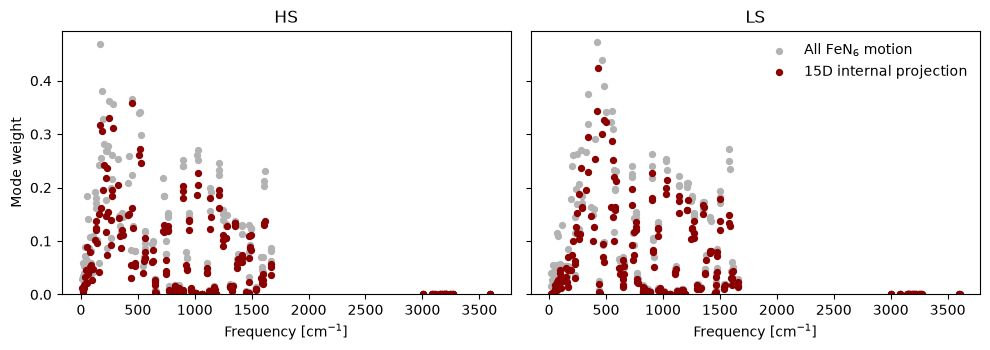

In [11]:
molecule = hs_min.molecules[0]
metal = molecule.metals[0]

metal_index = metal.get_parent_index('molecule')
fcs_indices = [metal_index] + metal.get_coord_sphere_idx()
assert len(fcs_indices) == 7, f'Expected FeN6, found {len(fcs_indices) - 1} coordinating atoms'

hs_fcs_weights, hs_internal_weights, hs_basis = project_vnms_on_fcs(vnmsA_ordered, results['alignment']['coordsA'], fcs_indices)
ls_fcs_weights, ls_internal_weights, ls_basis = project_vnms_on_fcs(vnmsB_ordered, results['alignment']['coordsB'], fcs_indices)

for label, basis, weights in [('HS', hs_basis, hs_internal_weights), ('LS', ls_basis, ls_internal_weights)]:
    effective_modes = np.sum(weights)**2 / np.sum(weights**2)
    print(f'{label}: basis={basis.shape}, sum={np.sum(weights):.3f}/15, maximum={np.max(weights):.3f}, effective modes={effective_modes:.1f}')

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, tight_layout=True)
for ax, vnms, fcs_weights, internal_weights, label in zip(axs, [vnmsA_ordered, vnmsB_ordered], [hs_fcs_weights, ls_fcs_weights], [hs_internal_weights, ls_internal_weights],['HS', 'LS']):
    frequencies = [vnm.freq_cm for vnm in vnms]
    ax.scatter(frequencies, fcs_weights, s=18, color='0.70', label='All FeN$_6$ motion')
    ax.scatter(frequencies, internal_weights, s=18, color='darkred', label='15D internal projection')
    ax.set_title(label)
    ax.set_xlabel(r'Frequency [cm$^{-1}$]')
    ax.set_ylim(bottom=0)

axs[0].set_ylabel('Mode weight')
axs[1].legend(frameon=False)
plt.show()

## Entropy-weighted FeN$_6$ internal contribution

For each mapped mode, SCOPE computes the harmonic vibrational entropy at the selected temperature. Its internal FeN$_6$ attribution is obtained by multiplying that entropy by the red projection weight:

$$S_{\mathrm{vib,FeN_6}}^X = \sum_i w_{i,\mathrm{FeN_6}}^X S_i^X, \qquad X \in \{\mathrm{HS},\mathrm{LS}\}.$$

The projected entropy difference is then $\Delta S_{\mathrm{vib,FeN_6}}=S_{\mathrm{vib,FeN_6}}^{\mathrm{HS}}-S_{\mathrm{vib,FeN_6}}^{\mathrm{LS}}$. This is an attribution of the entropy of collective molecular modes, not the thermodynamic entropy of an independently separable FeN$_6$ subsystem.

In [12]:
from scope.thermodynamics import get_Svib

temperature = 298.15

def get_mode_entropies(vnms, temperature):
    entropies = []
    for vnm in vnms:
        entropy = get_Svib([vnm.freq_cm], temperature, freq_units='cm', outunits='kj')
        entropies.append(entropy.value * 1000.0)
    return np.asarray(entropies)

hs_mode_entropies = get_mode_entropies(vnmsA_ordered, temperature)
ls_mode_entropies = get_mode_entropies(vnmsB_ordered, temperature)

delta_mode_entropies = hs_mode_entropies - ls_mode_entropies
hs_internal_entropies = hs_internal_weights * hs_mode_entropies
ls_internal_entropies = ls_internal_weights * ls_mode_entropies
delta_internal_entropies = hs_internal_entropies - ls_internal_entropies

delta_Svib = np.sum(delta_mode_entropies)
delta_Svib_internal = np.sum(delta_internal_entropies)

print(f'T = {temperature:.2f} K')
print(f'Total dSvib:          {delta_Svib:.2f} J mol-1 K-1')
print(f'Internal FeN6 dSvib: {delta_Svib_internal:.2f} J mol-1 K-1')
print(f'Attributed fraction: {100 * delta_Svib_internal / delta_Svib:.1f}%')

T = 298.15 K
Total dSvib:          72.01 J mol-1 K-1
Internal FeN6 dSvib: 22.98 J mol-1 K-1
Attributed fraction: 31.9%


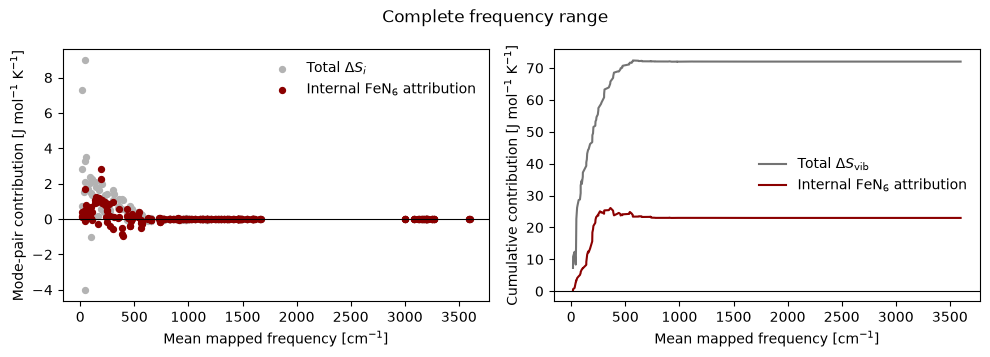

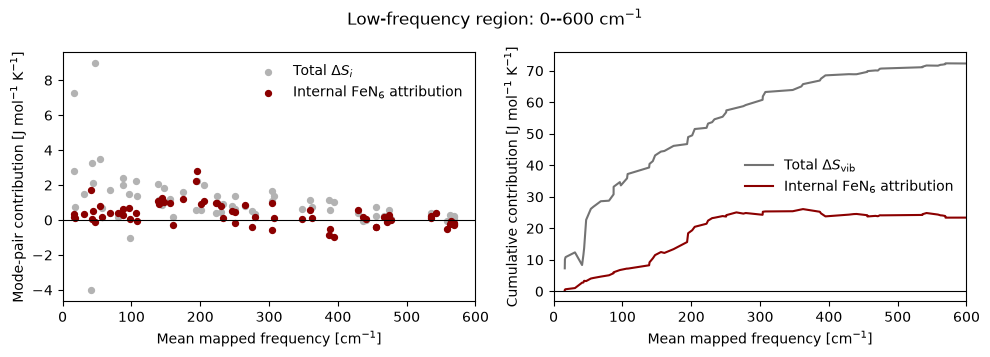

In [13]:
pair_frequencies = 0.5 * np.asarray([
    vnm_hs.freq_cm + vnm_ls.freq_cm
    for vnm_hs, vnm_ls in zip(vnmsA_ordered, vnmsB_ordered)
])
frequency_order = np.argsort(pair_frequencies)

def plot_entropy_contributions(max_frequency=None):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), tight_layout=True)

    axs[0].scatter(pair_frequencies, delta_mode_entropies, s=18, color='0.70', label=r'Total $\Delta S_i$')
    axs[0].scatter(pair_frequencies, delta_internal_entropies, s=18, color='darkred', label=r'Internal FeN$_6$ attribution')
    axs[0].axhline(0, color='black', linewidth=0.8)
    axs[0].set_xlabel(r'Mean mapped frequency [cm$^{-1}$]')
    axs[0].set_ylabel(r'Mode-pair contribution [J mol$^{-1}$ K$^{-1}$]')
    axs[0].legend(frameon=False)

    axs[1].plot(pair_frequencies[frequency_order], np.cumsum(delta_mode_entropies[frequency_order]), color='0.45', label=r'Total $\Delta S_{\mathrm{vib}}$')
    axs[1].plot(pair_frequencies[frequency_order], np.cumsum(delta_internal_entropies[frequency_order]), color='darkred', label=r'Internal FeN$_6$ attribution')
    axs[1].axhline(0, color='black', linewidth=0.8)
    axs[1].set_xlabel(r'Mean mapped frequency [cm$^{-1}$]')
    axs[1].set_ylabel(r'Cumulative contribution [J mol$^{-1}$ K$^{-1}$]')
    axs[1].legend(frameon=False)

    if max_frequency is None:
        fig.suptitle('Complete frequency range')
    else:
        for ax in axs:
            ax.set_xlim(0, max_frequency)
        fig.suptitle(rf'Low-frequency region: 0--{max_frequency} cm$^{{-1}}$')

    plt.show()


plot_entropy_contributions()
plot_entropy_contributions(max_frequency=600)

## Paired versus unpaired frequency resolution

The paired analysis assigns each HS--LS difference to the mean frequency of the modes matched by `map_vnms()`. The unpaired analysis retains the original frequency of every mode: HS contributions are added and LS contributions are subtracted independently. Both approaches must give the same final entropy difference, but they can distribute it differently across frequency.

In [14]:
hs_frequencies = np.asarray([vnm.freq_cm for vnm in vnmsA_ordered])
ls_frequencies = np.asarray([vnm.freq_cm for vnm in vnmsB_ordered])
frequency_grid = np.unique(np.concatenate([hs_frequencies, ls_frequencies, pair_frequencies]))

def cumulative_contribution(frequency_grid, frequencies, contributions):
    values = []
    for frequency in frequency_grid:
        values.append(np.sum(contributions[frequencies <= frequency]))
    return np.asarray(values)

paired_total_cumulative = cumulative_contribution(
    frequency_grid, pair_frequencies, delta_mode_entropies
)
unpaired_total_cumulative = (
    cumulative_contribution(frequency_grid, hs_frequencies, hs_mode_entropies)
    - cumulative_contribution(frequency_grid, ls_frequencies, ls_mode_entropies)
)

paired_internal_cumulative = cumulative_contribution(
    frequency_grid, pair_frequencies, delta_internal_entropies
)
unpaired_internal_cumulative = (
    cumulative_contribution(frequency_grid, hs_frequencies, hs_internal_entropies)
    - cumulative_contribution(frequency_grid, ls_frequencies, ls_internal_entropies)
)

print(f'Total endpoint, paired/unpaired:    {paired_total_cumulative[-1]:.3f} / {unpaired_total_cumulative[-1]:.3f}')
print(f'FeN6 endpoint, paired/unpaired:     {paired_internal_cumulative[-1]:.3f} / {unpaired_internal_cumulative[-1]:.3f}')
print(f'Maximum total cumulative difference: {np.max(np.abs(paired_total_cumulative - unpaired_total_cumulative)):.2f}')
print(f'Maximum FeN6 cumulative difference:  {np.max(np.abs(paired_internal_cumulative - unpaired_internal_cumulative)):.2f}')

Total endpoint, paired/unpaired:    72.006 / 72.006
FeN6 endpoint, paired/unpaired:     22.982 / 22.982
Maximum total cumulative difference: 84.04
Maximum FeN6 cumulative difference:  8.18


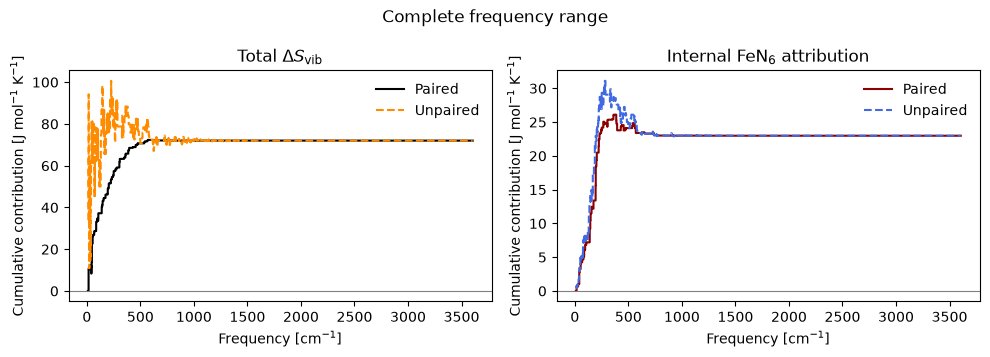

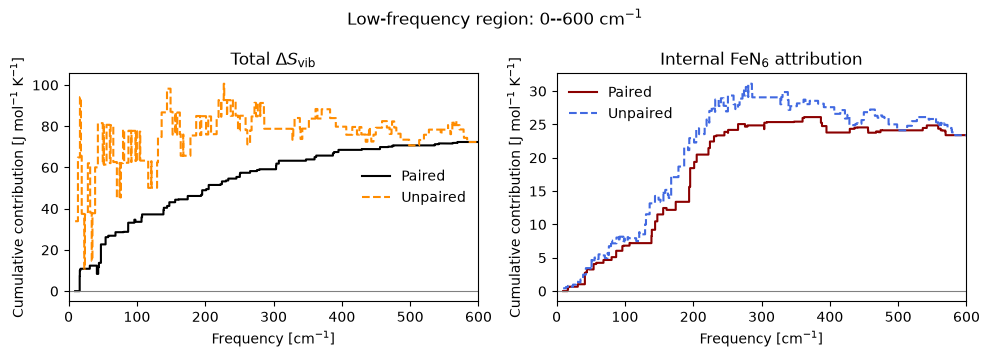

In [15]:
def plot_paired_unpaired_cumulative(max_frequency=None):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), tight_layout=True)

    axs[0].step(frequency_grid, paired_total_cumulative, where='post', color='black', label='Paired')
    axs[0].step(frequency_grid, unpaired_total_cumulative, where='post', color='darkorange', linestyle='--', label='Unpaired')
    axs[0].set_title(r'Total $\Delta S_{\mathrm{vib}}$')

    axs[1].step(frequency_grid, paired_internal_cumulative, where='post', color='darkred', label='Paired')
    axs[1].step(frequency_grid, unpaired_internal_cumulative, where='post', color='royalblue', linestyle='--', label='Unpaired')
    axs[1].set_title(r'Internal FeN$_6$ attribution')

    for ax in axs:
        ax.axhline(0, color='0.5', linewidth=0.8)
        ax.set_xlabel(r'Frequency [cm$^{-1}$]')
        ax.set_ylabel(r'Cumulative contribution [J mol$^{-1}$ K$^{-1}$]')
        ax.legend(frameon=False)
        if max_frequency is not None:
            ax.set_xlim(0, max_frequency)

    if max_frequency is None:
        fig.suptitle('Complete frequency range')
    else:
        fig.suptitle(rf'Low-frequency region: 0--{max_frequency} cm$^{{-1}}$')
    plt.show()


plot_paired_unpaired_cumulative()
plot_paired_unpaired_cumulative(max_frequency=600)

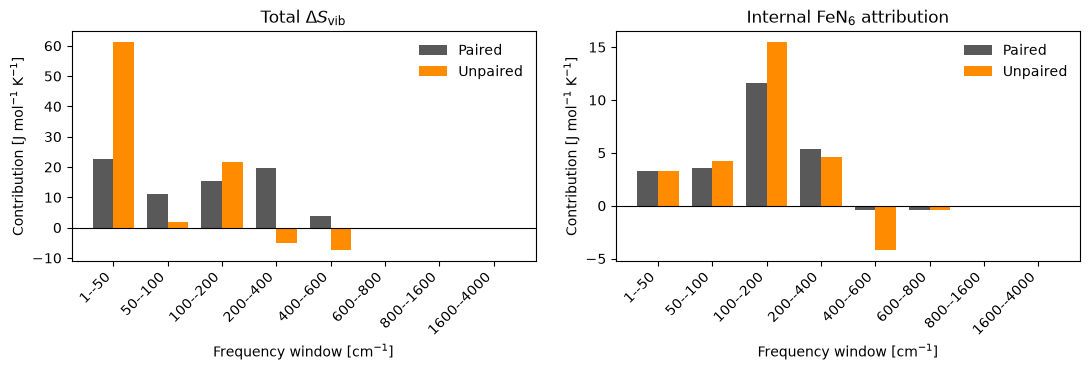

In [16]:
frequency_bins = np.asarray([1, 50, 100, 200, 400, 600, 800, 1600, 4000], dtype=float)
bin_labels = [f'{int(low)}--{int(high)}' for low, high in zip(frequency_bins[:-1], frequency_bins[1:])]

def bin_contributions(frequencies, contributions, bins):
    return np.histogram(frequencies, bins=bins, weights=contributions)[0]

paired_total_bins = bin_contributions(pair_frequencies, delta_mode_entropies, frequency_bins)
unpaired_total_bins = (
    bin_contributions(hs_frequencies, hs_mode_entropies, frequency_bins)
    - bin_contributions(ls_frequencies, ls_mode_entropies, frequency_bins)
)
paired_internal_bins = bin_contributions(pair_frequencies, delta_internal_entropies, frequency_bins)
unpaired_internal_bins = (
    bin_contributions(hs_frequencies, hs_internal_entropies, frequency_bins)
    - bin_contributions(ls_frequencies, ls_internal_entropies, frequency_bins)
)

x = np.arange(len(bin_labels))
width = 0.38
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), tight_layout=True)

for ax, paired, unpaired, title in zip(
    axs,
    [paired_total_bins, paired_internal_bins],
    [unpaired_total_bins, unpaired_internal_bins],
    [r'Total $\Delta S_{\mathrm{vib}}$', r'Internal FeN$_6$ attribution'],
):
    ax.bar(x - width / 2, paired, width, color='0.35', label='Paired')
    ax.bar(x + width / 2, unpaired, width, color='darkorange', label='Unpaired')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(x, bin_labels, rotation=45, ha='right')
    ax.set_xlabel(r'Frequency window [cm$^{-1}$]')
    ax.set_ylabel(r'Contribution [J mol$^{-1}$ K$^{-1}$]')
    ax.set_title(title)
    ax.legend(frameon=False)

plt.show()

## Ligand-resolved entropy attribution

`get_atomic_participation()` partitions the normalized mass-weighted amplitude of each molecular mode among its atoms. The atom indices belonging to each ligand are obtained with `lig.get_parent_indices('molecule')` and summed to give ligand weights. Because `map_vnms()` expresses the reordered LS modes in the HS atom order, the same ligand indices can be used for both states.

Unlike the internal FeN$_6$ projection, this partition retains every type of ligand motion, including internal deformation and rigid-like movement relative to the rest of the complex.

In [17]:
ligand_indices = [lig.get_parent_indices('molecule') for lig in molecule.ligands]
ligand_sizes = np.asarray([len(indices) for indices in ligand_indices])

grouped_indices = [metal_index]
for indices in ligand_indices:
    grouped_indices.extend(indices)
assert sorted(grouped_indices) == list(range(len(molecule.atoms))), 'Metal and ligand groups do not partition the molecule'

def get_ligand_metal_weights(vnms, ligand_indices, metal_index):
    ligand_weights = []
    metal_weights = []

    for vnm in vnms:
        atomic_participation = vnm.get_atomic_participation()
        this_ligand_weights = []
        for indices in ligand_indices:
            this_ligand_weights.append(np.sum(atomic_participation[indices]))

        ligand_weights.append(this_ligand_weights)
        metal_weights.append(atomic_participation[metal_index])

    return np.asarray(ligand_weights), np.asarray(metal_weights)

hs_ligand_weights, hs_metal_weights = get_ligand_metal_weights(
    vnmsA_ordered, ligand_indices, metal_index
)
ls_ligand_weights, ls_metal_weights = get_ligand_metal_weights(
    vnmsB_ordered, ligand_indices, metal_index
)

hs_partition = np.sum(hs_ligand_weights, axis=1) + hs_metal_weights
ls_partition = np.sum(ls_ligand_weights, axis=1) + ls_metal_weights
print(f'Maximum HS partition error: {np.max(np.abs(hs_partition - 1)):.2e}')
print(f'Maximum LS partition error: {np.max(np.abs(ls_partition - 1)):.2e}')

Maximum HS partition error: 6.66e-16
Maximum LS partition error: 4.44e-16


In [18]:
hs_ligand_entropies = hs_ligand_weights * hs_mode_entropies[:, None]
ls_ligand_entropies = ls_ligand_weights * ls_mode_entropies[:, None]
delta_ligand_entropies = hs_ligand_entropies - ls_ligand_entropies

hs_metal_entropies = hs_metal_weights * hs_mode_entropies
ls_metal_entropies = ls_metal_weights * ls_mode_entropies
delta_metal_entropies = hs_metal_entropies - ls_metal_entropies

ligand_entropy_totals = np.sum(delta_ligand_entropies, axis=0)
metal_entropy_total = np.sum(delta_metal_entropies)
recovered_entropy = np.sum(ligand_entropy_totals) + metal_entropy_total

print('Group       Num atoms    dSvib [J mol-1 K-1]    dSvib/atom')
for idx, (num_atoms, entropy) in enumerate(zip(ligand_sizes, ligand_entropy_totals), start=1):
    print(f'Ligand {idx:<2}  {num_atoms:>9}    {entropy:>19.2f}    {entropy / num_atoms:>10.3f}')
print(f'Metal      {1:>9}    {metal_entropy_total:>19.2f}    {metal_entropy_total:>10.3f}')
print()
print(f'Mean per ligand:  {np.mean(ligand_entropy_totals):.2f} J mol-1 K-1')
print(f'All ligands:      {np.sum(ligand_entropy_totals):.2f} J mol-1 K-1')
print(f'Recovered dSvib:  {recovered_entropy:.2f} J mol-1 K-1')
print(f'Direct dSvib:     {delta_Svib:.2f} J mol-1 K-1')

Group       Num atoms    dSvib [J mol-1 K-1]    dSvib/atom
Ligand 1          26                  22.77         0.876
Ligand 2          26                  16.38         0.630
Ligand 3          26                  21.77         0.837
Metal              1                  11.08        11.079

Mean per ligand:  20.31 J mol-1 K-1
All ligands:      60.93 J mol-1 K-1
Recovered dSvib:  72.01 J mol-1 K-1
Direct dSvib:     72.01 J mol-1 K-1


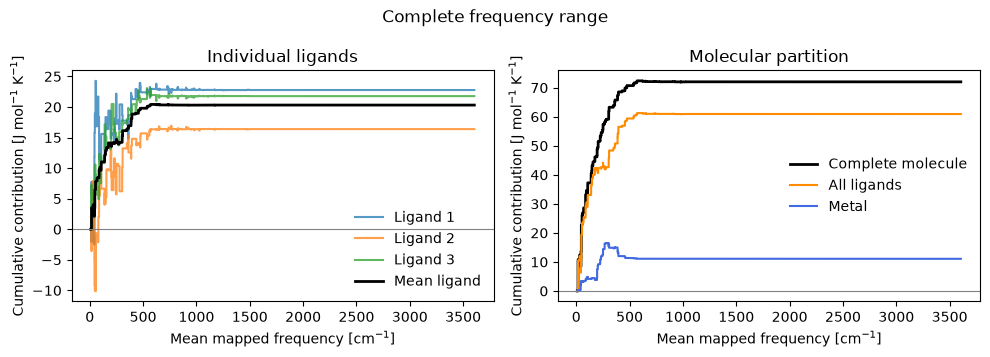

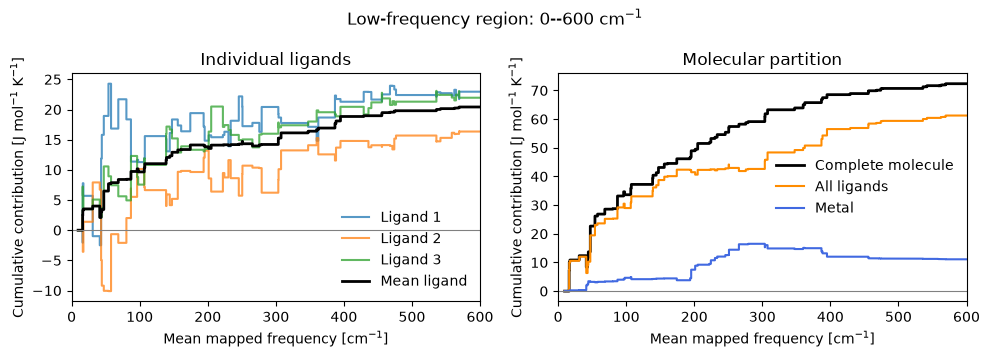

In [19]:
ligand_cumulative = []
for idx in range(len(ligand_indices)):
    ligand_cumulative.append(
        cumulative_contribution(frequency_grid, pair_frequencies, delta_ligand_entropies[:, idx])
    )
ligand_cumulative = np.asarray(ligand_cumulative)

metal_cumulative = cumulative_contribution(
    frequency_grid, pair_frequencies, delta_metal_entropies
)
all_ligands_cumulative = np.sum(ligand_cumulative, axis=0)

def plot_ligand_contributions(max_frequency=None):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), tight_layout=True)

    colors = plt.get_cmap('tab10').colors
    for idx, values in enumerate(ligand_cumulative):
        axs[0].step(frequency_grid, values, where='post', color=colors[idx], alpha=0.75, label=f'Ligand {idx + 1}')
    axs[0].step(frequency_grid, np.mean(ligand_cumulative, axis=0), where='post', color='black', linewidth=2, label='Mean ligand')
    axs[0].set_title('Individual ligands')

    axs[1].step(frequency_grid, paired_total_cumulative, where='post', color='black', linewidth=2, label='Complete molecule')
    axs[1].step(frequency_grid, all_ligands_cumulative, where='post', color='darkorange', label='All ligands')
    axs[1].step(frequency_grid, metal_cumulative, where='post', color='royalblue', label='Metal')
    axs[1].set_title('Molecular partition')

    for ax in axs:
        ax.axhline(0, color='0.5', linewidth=0.8)
        ax.set_xlabel(r'Mean mapped frequency [cm$^{-1}$]')
        ax.set_ylabel(r'Cumulative contribution [J mol$^{-1}$ K$^{-1}$]')
        ax.legend(frameon=False)
        if max_frequency is not None:
            ax.set_xlim(0, max_frequency)

    if max_frequency is None:
        fig.suptitle('Complete frequency range')
    else:
        fig.suptitle(rf'Low-frequency region: 0--{max_frequency} cm$^{{-1}}$')
    plt.show()


plot_ligand_contributions()
plot_ligand_contributions(max_frequency=600)